# imports

In [19]:
import sys
import os
import json

import matplotlib
import numpy as np
import scipy as sp
import pandas as pd

import importlib

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from utils import analysis_utils

from utils import ai_slob

In [20]:
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(analysis_utils)

importlib.reload(ai_slob)

<module 'utils.ai_slob' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/ai_slob.py'>

In [21]:
# specific

sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_mouse import read_utils
sys.path.append(os.path.join(os.getcwd(), '../../../mouse-control/src'))
from utils_mouse_control import read_utils as read_utils_control

In [22]:
importlib.reload(read_utils)
importlib.reload(read_utils_control)

<module 'utils_mouse_control.read_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/mouse-control/src/utils_mouse_control/read_utils.py'>

# setup

In [23]:
ll = 'll00'
data_variant = 'gcamp'

In [24]:
# specific

model_variant = 'ss'
organism = 'mouse'
manual = False
full = False

In [25]:
file_id = 2
save = True

# load

In [26]:
state_key, state_label = analysis_utils.get_plot_class(organism)
model_path = read_utils.get_model_path()

filename = analysis_utils.read_filename(organism, file_id)
metadata = (filename, model_path, model_variant, data_variant, manual, full)

# scores

In [27]:
((bom_spn, _, _, _, _, _, _),
 (hgm_spn, _, _, _, _, _, _)) = analysis_utils.read_predictions(*metadata)

neuron_scores = analysis_utils.assemble_scoress([bom_spn], [hgm_spn])

In [ ]:
# plot_utils.plot_performance_plot(
# 	neuron_scores, None,
# 	title='r2 scores for all neurons', limits=None,
# 	save_path=f'../../out/plots/scores/shuffle_control/{filename}/{model_variant}_scores_all' if save else None
# )

In [ ]:
# if organism == 'worm' and not all([key[0].isdigit() for key in neuron_scores]):
# 	plot_utils.plot_performance_plot(
# 		{key: neuron_scores[key] for key in neuron_scores.keys() if not key[0].isdigit()}, None,
# 		title='r2 scores for ID\'d neurons', limits=None,
# 		save_path=f'../../out/plots/scores/shuffle_control/{filename}/{model_variant}_scores_id' if save else None
# 	)

# shuffle control

In [28]:
shuffles = sum(folder.startswith('shuffle_') for folder in os.listdir(os.path.join(read_utils_control.get_model_path(0), '..'))) - 1

In [29]:
boms_spn, hgms_spn = list(), list()
for shuffle_id in range(shuffles):
	((bom_spn, _, _, _, _, _, _),
	 (hgm_spn, _, _, _, _, _, _)) = analysis_utils.read_scores(filename, read_utils_control.get_model_path(shuffle_id), model_variant, data_variant, manual, full)
	boms_spn.append(bom_spn)
	hgms_spn.append(hgm_spn)

neuron_scores_shuffle = analysis_utils.assemble_scoress(boms_spn, hgms_spn)

In [ ]:
plot_utils.plot_performance_plot(
	neuron_scores, neuron_scores_shuffle,
	title='r2 scores for all neurons (+control)', limits=None,
	horizontal_bps=False, force_medians=False, threshold=None,
	save_path=f'../../out/plots/scores/shuffle_control/{filename}/{model_variant}_scores_control' if save else None
)

In [ ]:
if organism == 'worm' and not all([key[0].isdigit() for key in neuron_scores]):
	plot_utils.plot_performance_plot(
		{key: neuron_scores[key] for key in neuron_scores.keys() if not key[0].isdigit()},
		{key: neuron_scores_shuffle[key] for key in neuron_scores_shuffle.keys() if not key[0].isdigit()},
		title='r2 scores for ID\'d neurons (+control)', limits=None,
		horizontal_bps=False, force_medians=False, threshold=None,
		save_path=f'../../out/plots/scores/shuffle_control/{filename}/{model_variant}_scores_id_control' if save else None
	)

In [30]:
# percentiles_bom = ai_slob.compute_neuron_percentiles(
#     neuron_scores,
#     neuron_scores_shuffle,
#     model='bom'
# )

percentiles_hgm = ai_slob.compute_neuron_percentiles(
    neuron_scores,
    neuron_scores_shuffle,
    model='hgm'
)

percentiles_impr = ai_slob.compute_neuron_percentiles(
    neuron_scores,
    neuron_scores_shuffle,
    model='improvement'
)

In [ ]:
# ai_slob.plot_percentile_hist(percentiles_bom,
# 							 title='BOM r2 percentiles', threshold=100, bins=shuffles,
# 							 save_path=f'../../out/plots/scores/shuffle_control/{filename}/{model_variant}_bom_percentiles' if save else None)

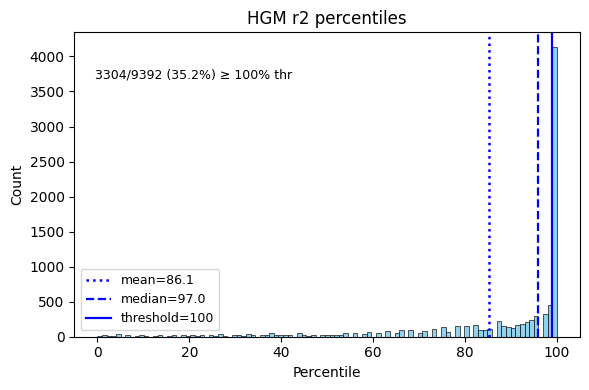

(<Figure size 600x400 with 1 Axes>,
 <Axes: title={'center': 'HGM r2 percentiles'}, xlabel='Percentile', ylabel='Count'>)

In [31]:
ai_slob.plot_percentile_hist(percentiles_hgm,
							 title='HGM r2 percentiles', threshold=100, bins=shuffles,
							 save_path=f'../../out/plots/scores/shuffle_control/{filename}/{model_variant}_hgm_percentiles' if save else None)

In [33]:
neuron_scores_significant = {key: value for key, value in neuron_scores.items() if neuron_scores[key][0] >= 0 and neuron_scores[key][1] >= 0 and percentiles_hgm[key] >= 100.0}
neuron_scores_significant = dict(sorted(neuron_scores_significant.items(), key=lambda x: x[1][1], reverse=True))
neuron_scores_significant = dict(sorted(neuron_scores_significant.items(), key=lambda x: x[1][1] - x[1][0], reverse=True))

In [34]:
p_values_sig_impr = ai_slob.percentile_to_p_value_one_sided(percentiles_impr)

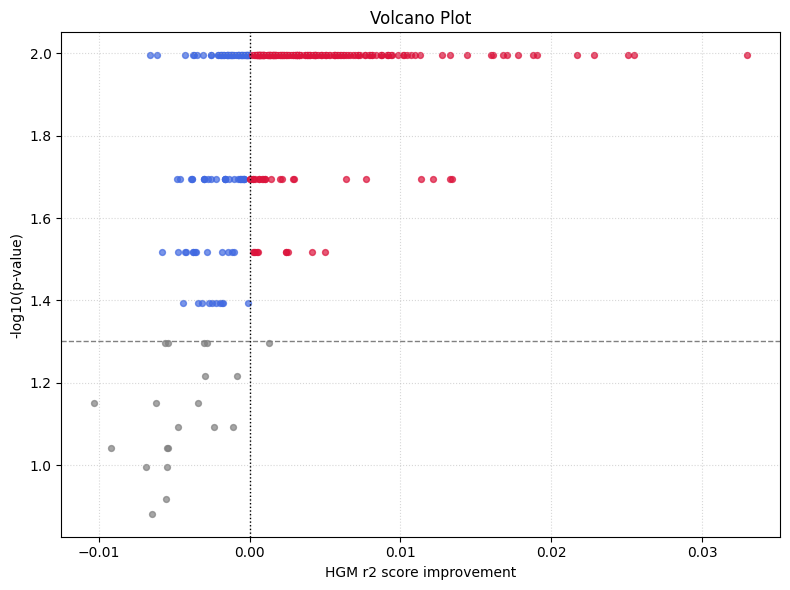

In [35]:
ai_slob.volcano_plot(neuron_scores_significant, p_values_sig_impr, model='improvement', n_label=None,
					 save_path=f'../../out/plots/scores/shuffle_control/{filename}/{model_variant}_impr_volcano' if save else None)

In [36]:
neuron_scores_significant_impr = {key: value for key, value in neuron_scores_significant.items() if p_values_sig_impr[key] == min(p_values_sig_impr.values())}
neuron_scores_significant_impr = dict(sorted(neuron_scores_significant_impr.items(), key=lambda x: x[1][1] - x[1][0], reverse=True))

In [37]:
os.makedirs(f'../../out/data/significant_neurons/{filename}/', exist_ok=True)

pd.DataFrame(neuron_scores_significant).to_pickle(f'../../out/data/significant_neurons/{filename}/{model_variant}_hgm.pkl')
pd.DataFrame(neuron_scores_significant_impr).to_pickle(f'../../out/data/significant_neurons/{filename}/{model_variant}_impr.pkl')

In [38]:
print(f'\'{'\', \''.join([neuron_label for neuron_label in neuron_scores_significant_impr.keys()])}\'')

'02_8146', '02_2174', '02_7204', '02_2214', '02_7412', '02_5545', '02_1408', '02_1246', '02_6505', '02_6212', '02_233', '02_4429', '02_1107', '02_5477', '02_1057', '02_8307', '02_5548', '02_7446', '02_130', '02_6502', '02_1200', '02_023', '02_030', '02_1327', '02_236', '02_8195', '02_3736', '02_086', '02_7249', '02_3761', '02_1062', '02_6203', '02_6449', '02_5486', '02_7398', '02_7829', '02_1102', '02_1321', '02_3368', '02_7525', '02_5448', '02_7260', '02_2068', '02_5483', '02_7331', '02_2011', '02_7309', '02_3796', '02_2265', '02_7405', '02_7244', '02_8871', '02_2099', '02_7355', '02_3973', '02_1027', '02_5508', '02_9002', '02_2101', '02_7490', '02_8288', '02_974', '02_3143', '02_7569', '02_6267', '02_9016', '02_8242', '02_8958', '02_3967', '02_8317', '02_5408', '02_1270', '02_5341', '02_462', '02_3993', '02_8069', '02_325', '02_372', '02_7527', '02_5506', '02_8940', '02_4740', '02_2572', '02_6801', '02_6546', '02_6601', '02_306', '02_8297', '02_7549', '02_6586', '02_1042', '02_9170',

In [39]:
print(f'\'{'\', \''.join([neuron_label for neuron_label in neuron_scores_significant_impr.keys() if not neuron_label[0].isdigit()])}\'')

''


In [ ]:
# ai_slob.plot_control_histograms(neuron_scores, neuron_scores_shuffle, list(neuron_scores_significant_impr.keys())[:100],
# 								model='hgm',
# 								save_path=f'../../out/plots/scores/shuffle_control/{filename}/{model_variant}_neurons' if save else None)
# pass

In [ ]:
# def assemble_scoress_unsorted(boms_scores_per_neuron, hgms_scores_per_neuron):
# 	neurons_labels = [scores_per_neuron[0].columns for scores_per_neuron in hgms_scores_per_neuron]
#
# 	boms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in boms_scores_per_neuron]
# 	hgms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in hgms_scores_per_neuron]
#
# 	neuron_scores = dict()
# 	boms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in boms_scores_per_neuron]
# 	hgms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in hgms_scores_per_neuron]
# 	for label_list, score_bom_list, score_hgm_list in zip(neurons_labels, boms_scores_per_neuron_avg,
# 														  hgms_scores_per_neuron_avg):
# 		for i in range(len(label_list)):
# 			label = label_list[i]
# 			if label != '' and label[-1] != '_':
# 				score_bom_new, score_hgm_new = np.array(score_bom_list[i]), np.array(score_hgm_list[i])
# 				if len(score_hgm_new.shape) == 0:
# 					score_bom_new = score_bom_new.reshape(1, 1)
# 					score_hgm_new = score_hgm_new.reshape(1, 1)
# 				if label not in neuron_scores.keys():
# 					neuron_scores[label] = (score_bom_new, score_hgm_new)
# 				else:
# 					score_bom_prev, score_hgm_prev = neuron_scores[label]
# 					neuron_scores[label] = (np.vstack([score_bom_prev, score_bom_new]),
# 											np.vstack([score_hgm_prev, score_hgm_new]))
#
# 	return neuron_scores
#
#
# neuron_scores_unsorted = assemble_scoress_unsorted([bom_spn], [hgm_spn])
# neuron_scores_unsorted = np.array([item[1][1].squeeze() for item in neuron_scores_unsorted.items()])
# neuron_scores_unsorted_zsc = (neuron_scores_unsorted - neuron_scores_unsorted.mean(axis=0)) / np.where((N_std := neuron_scores_unsorted.std(axis=0)) == 0.0, 1.0, N_std)

In [ ]:
# import matplotlib.pyplot as plt
# from mpl_toolkits.mplot3d import Axes3D

In [ ]:
# path = path = os.path.join(read_utils.get_data_path(), '6163622/sessions')
# position = sp.io.loadmat(os.path.join(path, filename), variable_names=['med'])['med']

In [ ]:
# fig = plt.figure(figsize=(10, 10))
# ax = fig.add_subplot(111, projection='3d')
#
# ax.scatter(position[:, 0], position[:, 1], position[:, 2], s=2, c=neuron_scores_unsorted_zsc, cmap='viridis')
# plt.show()